In [7]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

# --- 1. PATH CONFIGURATION ---
DATA_DIRS = {
    "LUNA16": f"{PROJECT_ROOT}/extracted_patches/LUNA16",
    "LIDC":   f"{PROJECT_ROOT}/extracted_patches/LIDC_IDRI",
    "LNDb":   f"{PROJECT_ROOT}/extracted_patches/LNDb"
}

OUTPUT_DIR = f"{PROJECT_ROOT}/master_dataset"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [10]:
# --- 2. PATIENT ID EXTRACTION FUNCTION ---
def extract_patient_id(file_path, dataset_name):
    filename = os.path.basename(file_path)

    if dataset_name == "LUNA16":
        # Filenames produced by 00_extract_luna16.ipynb:
        #   Pass 1: {seriesuid}_x{vx}.png
        #   Pass 2-3: {seriesuid}_x{vx}_z{vz}.png
        # The LUNA16 seriesuid is a dot-separated string of digits
        # (e.g. "1.3.6.1.4.1.14519.5.2.1.6279.6001.123456789"), so no ambiguity.
        return filename.split('_x')[0]

    elif dataset_name == "LIDC":
        # Expected format: "LIDC-IDRI-XXXX_..."
        parts = filename.split('_')
        return parts[0] # Returns LIDC-IDRI-XXXX

    elif dataset_name == "LNDb":
        # Expected format: "LNDb-XXXX_..."
        parts = filename.split('_')
        return parts[0] # Returns LNDb-XXXX

    return "unknown"


In [11]:
# --- 3. IMPROVED SCAN FUNCTION ---
def create_master_dataframe():
    data = []
    print("📂 Consolidating datasets with Patient ID extraction...")

    for dataset_name, root_path in DATA_DIRS.items():
        if not os.path.exists(root_path):
            print(f"⚠️ {dataset_name} not found at: {root_path}")
            continue

        print(f"✅ Reading: {dataset_name} ...")

        for class_id in [0, 1, 2]:
            class_path = os.path.join(root_path, f"class_{class_id}")
            if not os.path.exists(class_path): continue

            files = glob.glob(os.path.join(class_path, "*.png"))
            if len(files) > 0:
                print(f"   -> Class {class_id}: {len(files)} images")
                for f in files:
                    patient_id = extract_patient_id(f, dataset_name)
                    data.append({
                        "path": f,
                        "label": class_id,
                        "source": dataset_name,
                        "patient_id": patient_id
                    })

    return pd.DataFrame(data)


📂 Consolidating datasets with Patient ID extraction...
✅ Reading: LUNA16 ...
   -> Class 0: 16071 images
✅ Reading: LIDC ...
   -> Class 1: 9303 images
   -> Class 2: 2008 images
✅ Reading: LNDb ...
   -> Class 0: 402 images
   -> Class 1: 1040 images
   -> Class 2: 8352 images

 FINAL DATASET TOTAL: 37176 images
 TOTAL UNIQUE PATIENTS: 1517

 Train/Val/Test split by Patient ID...

📊 Patient distribution by patient-level label:
patient_label
0    595
1    381
2    541
Name: count, dtype: int64
   📂 Train: 25852 images (1061 patients)
   📂 Val  : 5796 images (228 patients)
   📂 Test : 5528 images (228 patients)

 Checking patient overlap:
Train ∩ Val  = 0
Train ∩ Test = 0
Val ∩ Test   = 0
✅ No patient overlap detected.


/tmp/ipykernel_2161/4255143460.py:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='label', data=train_df, palette='viridis')


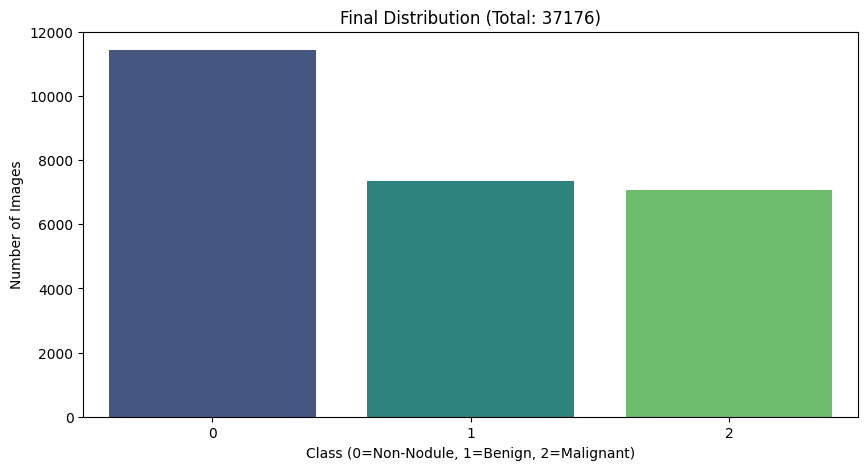


 Files saved in: /content/drive/MyDrive/lung_nodule_classification/master_dataset
Data leakage is now resolved.


In [12]:
# --- 4. EXECUTION AND PATIENT-LEVEL SPLIT ---
df = create_master_dataframe()

if len(df) == 0:
    print("❌ Error: No images found.")
else:
    print(f"\n FINAL DATASET TOTAL: {len(df)} images")
    print(f" TOTAL UNIQUE PATIENTS: {df['patient_id'].nunique()}")

    # --- PATIENT-LEVEL LABEL FUNCTION ---
    def patient_level_label(labels):
        labels = set(labels)
        if 2 in labels:
            return 2
        elif 1 in labels:
            return 1
        return 0

    # --- PATIENT-LEVEL SPLIT ---
    print("\n Train/Val/Test split by Patient ID...")

    # Patient-level metadata for stratification
    patient_meta = (
        df.groupby('patient_id')['label']
          .agg(lambda x: patient_level_label(x.tolist()))
          .reset_index(name='patient_label')
    )

    print("\n📊 Patient distribution by patient-level label:")
    print(patient_meta['patient_label'].value_counts().sort_index())

    # 70% Train / 30% Temp
    train_patients, temp_patients = train_test_split(
        patient_meta['patient_id'],
        test_size=0.3,
        stratify=patient_meta['patient_label'],
        random_state=42
    )

    # 15% Val / 15% Test
    temp_meta = patient_meta[patient_meta['patient_id'].isin(temp_patients)]

    val_patients, test_patients = train_test_split(
        temp_meta['patient_id'],
        test_size=0.5,
        stratify=temp_meta['patient_label'],
        random_state=42
    )

    # Build the final DataFrames
    train_df = df[df['patient_id'].isin(train_patients)].copy()
    val_df   = df[df['patient_id'].isin(val_patients)].copy()
    test_df  = df[df['patient_id'].isin(test_patients)].copy()

    print(f"   📂 Train: {len(train_df)} images ({len(train_patients)} patients)")
    print(f"   📂 Val  : {len(val_df)} images ({len(val_patients)} patients)")
    print(f"   📂 Test : {len(test_df)} images ({len(test_patients)} patients)")

    # --- ANTI-LEAKAGE CHECK ---
    train_pat_set = set(train_df['patient_id'].unique())
    val_pat_set   = set(val_df['patient_id'].unique())
    test_pat_set  = set(test_df['patient_id'].unique())

    print("\n Checking patient overlap:")
    print("Train ∩ Val  =", len(train_pat_set & val_pat_set))
    print("Train ∩ Test =", len(train_pat_set & test_pat_set))
    print("Val ∩ Test   =", len(val_pat_set & test_pat_set))

    assert train_pat_set.isdisjoint(val_pat_set), "❌ Leakage: Train and Val share patients"
    assert train_pat_set.isdisjoint(test_pat_set), "❌ Leakage: Train and Test share patients"
    assert val_pat_set.isdisjoint(test_pat_set), "❌ Leakage: Val and Test share patients"

    print("✅ No patient overlap detected.")

    # --- SAVE ---
    train_df.to_csv(os.path.join(OUTPUT_DIR, "train.csv"), index=False)
    val_df.to_csv(os.path.join(OUTPUT_DIR, "val.csv"), index=False)
    test_df.to_csv(os.path.join(OUTPUT_DIR, "test.csv"), index=False)

    # --- VISUALIZATION ---
    plt.figure(figsize=(10, 5))
    sns.countplot(x='label', data=train_df, palette='viridis')
    plt.title(f"Final Distribution (Total: {len(df)})")
    plt.xlabel("Class (0=Non-Nodule, 1=Benign, 2=Malignant)")
    plt.ylabel("Number of Images")
    plt.show()

    print(f"\n Files saved in: {OUTPUT_DIR}")
    print("Data leakage is now resolved.")


In [13]:
print("Class distribution per split:\n")
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    counts = d['label'].value_counts().sort_index()
    total = len(d)
    print(f"{name} ({total} images):")
    for cls in [0, 1, 2]:
        n = counts.get(cls, 0)
        print(f"   Class {cls}: {n:5d} ({n/total*100:.1f}%)")
    print()

print("\n📊 Distribution by source within each split:")
for name, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"\n{name}:")
    print(d.groupby(['source', 'label']).size().unstack(fill_value=0))


Class distribution per split:

Train (25852 images):
   Class 0: 11430 (44.2%)
   Class 1:  7346 (28.4%)
   Class 2:  7076 (27.4%)

Val (5796 images):
   Class 0:  2715 (46.8%)
   Class 1:  1569 (27.1%)
   Class 2:  1512 (26.1%)

Test (5528 images):
   Class 0:  2328 (42.1%)
   Class 1:  1428 (25.8%)
   Class 2:  1772 (32.1%)


📊 Distribution by source within each split:

Train:
label       0     1     2
source                   
LIDC        0  6626  1428
LNDb      264   720  5648
LUNA16  11166     0     0

Val:
label      0     1     2
source                  
LIDC       0  1457   344
LNDb      63   112  1168
LUNA16  2652     0     0

Test:
label      0     1     2
source                  
LIDC       0  1220   236
LNDb      75   208  1536
LUNA16  2253     0     0


In [17]:
print("\nTrain class distribution:")
print(train_df['label'].value_counts().sort_index())

print("\nVal class distribution:")
print(val_df['label'].value_counts().sort_index())

print("\nTest class distribution:")
print(test_df['label'].value_counts().sort_index())


Train class distribution:
label
0    11430
1     7346
2     7076
Name: count, dtype: int64

Val class distribution:
label
0    2715
1    1569
2    1512
Name: count, dtype: int64

Test class distribution:
label
0    2328
1    1428
2    1772
Name: count, dtype: int64


In [18]:
def patient_level_label(labels):
    labels = set(labels)
    if 2 in labels:
        return 2
    elif 1 in labels:
        return 1
    return 0

print("\nTrain patient-level distribution:")
print(train_df.groupby('patient_id')['label'].apply(patient_level_label).value_counts().sort_index())

print("\nVal patient-level distribution:")
print(val_df.groupby('patient_id')['label'].apply(patient_level_label).value_counts().sort_index())

print("\nTest patient-level distribution:")
print(test_df.groupby('patient_id')['label'].apply(patient_level_label).value_counts().sort_index())


Train patient-level distribution:
label
0    416
1    267
2    378
Name: count, dtype: int64

Val patient-level distribution:
label
0    89
1    57
2    82
Name: count, dtype: int64

Test patient-level distribution:
label
0    90
1    57
2    81
Name: count, dtype: int64
